In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Jalankan notebook dari folder proyek; file cleaned berada di folder data/cleaned.
df = pd.read_csv(
    '../data/cleaned/Sample-Superstore-Cleaned.csv',
    dtype={'postal_code': 'string'},
    parse_dates=['order_date', 'ship_date']
)

print('Ukuran dataset:', df.shape)
display(df.head())
display(df.dtypes)


Ukuran dataset: (9993, 20)


,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_duration
0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3
2,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4
3,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7


order_id                     object
order_date           datetime64[ns]
ship_date            datetime64[ns]
ship_mode                    object
customer_id                  object
customer_name                object
segment                      object
city                         object
state                        object
postal_code          string[python]
region                       object
product_id                   object
category                     object
sub_category                 object
product_name                 object
sales                       float64
quantity                      int64
discount                    float64
profit                      float64
shipping_duration             int64
dtype: object

In [2]:
total_sales = df['sales'].sum()
total_profit = df['profit'].sum()
profit_margin = (total_profit / total_sales) * 100

total_orders = df['order_id'].nunique()
total_customers = df['customer_id'].nunique()
avg_order_value = total_sales / total_orders

margin_rata2_baris = (df['profit'] / df['sales']).mean() * 100
print(f'Margin total: {profit_margin:.2f}% | Rata-rata margin per baris: {margin_rata2_baris:.2f}%')

Margin total: 12.47% | Rata-rata margin per baris: 12.03%


In [3]:
kpi = pd.DataFrame({
    'KPI': [
        'Total Sales',
        'Total Profit',
        'Profit Margin',
        'Total Orders',
        'Total Customers',
        'Average Order Value'
    ],
    'Value': [
        total_sales,
        total_profit,
        profit_margin,
        total_orders,
        total_customers,
        avg_order_value
    ]
})

display(kpi.round(2))

,KPI,Value
0,Total Sales,2296919.49
1,Total Profit,286409.08
2,Profit Margin,12.47
3,Total Orders,5009.00
4,Total Customers,793.00
5,Average Order Value,458.56


*Berdasarkan perhitungan KPI dasar, total penjualan mencapai 2,296,919 dengan total profit sebesar 286,409 Profit margin sebesar 12,47%, yang berarti perusahaan memperoleh profit sekitar 12,47% dari total nilai penjualannya.margin total (12,47%) dihitung dari seluruh profit dibagi seluruh sales sehingga transaksi besar berbobot lebih besar, sedangkan rata-rata margin per baris (12,03%) memperlakukan semua baris setara. Yang dilaporkan adalah margin total. Dataset mencatat 5009 pesanan unik dari 793 pelanggan, dengan rata-rata nilai pesanan sebesar 458.*

In [4]:
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['quarter'] = df['order_date'].dt.quarter
df['quarter_name'] = 'Q' + df['quarter'].astype(str)
df['year_month'] = df['order_date'].dt.to_period('M')

display(
    df[['order_date', 'year', 'quarter_name', 'month', 'year_month']].head()
)

,order_date,year,quarter_name,month,year_month
0,2016-11-08,2016,Q4,11,2016-11
1,2016-11-08,2016,Q4,11,2016-11
2,2016-06-12,2016,Q2,6,2016-06
3,2015-10-11,2015,Q4,10,2015-10
4,2015-10-11,2015,Q4,10,2015-10


**Visualisasi Trend Tahunan**

In [5]:
yearly_trend = df.groupby('year').agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum'),
    orders=('order_id', 'nunique')
).reset_index()
yearly_trend['aov'] = yearly_trend['total_sales'] / yearly_trend['orders']

In [6]:
yearly_trend['sales_growth'] = yearly_trend['total_sales'].pct_change() * 100
yearly_trend['profit_growth'] = yearly_trend['total_profit'].pct_change() * 100
yearly_trend['margin_%'] = yearly_trend['total_profit'] / yearly_trend['total_sales'] * 100

display(yearly_trend.round(2))

,year,total_sales,total_profit,orders,aov,sales_growth,profit_growth,margin_%
0,2014,483966.13,49556.03,969,499.45,NaN,NaN,10.24
1,2015,470532.51,61618.60,1038,453.31,-2.78,24.34,13.10
2,2016,609205.60,81795.17,1315,463.27,29.47,32.74,13.43
3,2017,733215.26,93439.27,1687,434.63,20.36,14.24,12.74


*Sales tumbuh 51,5% (483.966 → 733.215) dan profit tumbuh 88,5% (49.556 → 93.439) dari 2014 ke 2017. Namun di 2017 profit tumbuh 14% sementara sales tumbuh 20%, dan margin turun dari 13,4% ke 12,7%. Pesanan naik 74% tetapi rata-rata nilai per pesanan turun 13% (499 → 435), jadi pertumbuhan sales didorong oleh jumlah pesanan, bukan nilai tiap pesanan.*

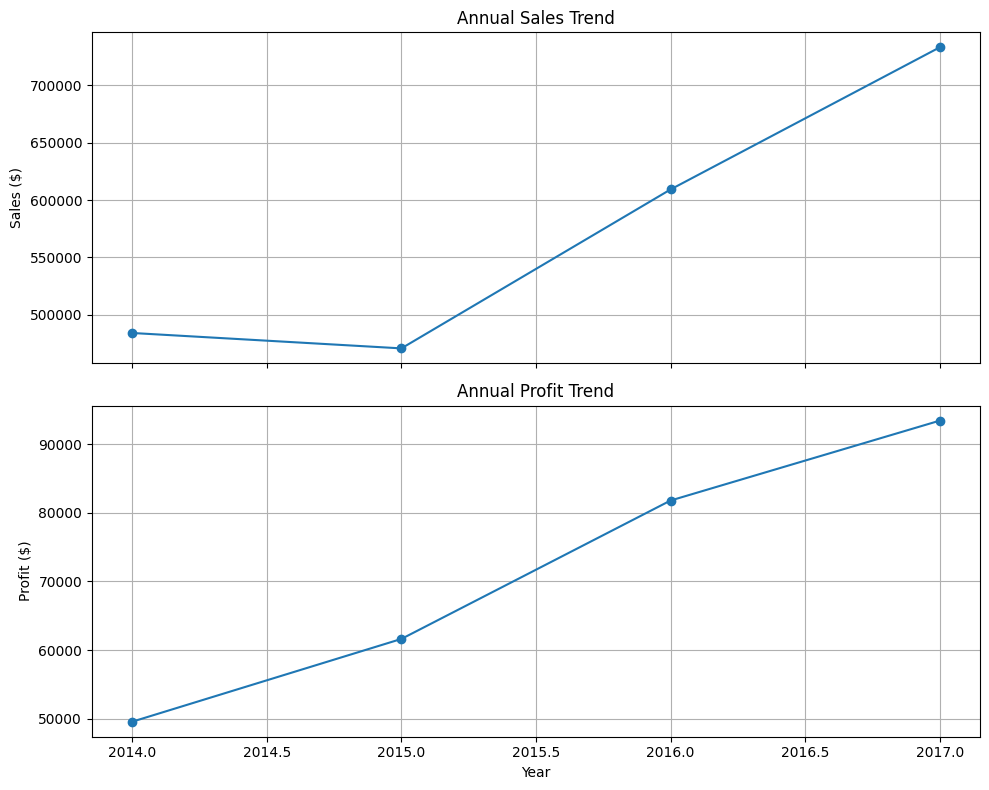

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axes[0].plot(yearly_trend['year'], yearly_trend['total_sales'], marker='o')
axes[0].set_title('Annual Sales Trend')
axes[0].set_ylabel('Sales ($)')
axes[0].grid(True)

axes[1].plot(yearly_trend['year'], yearly_trend['total_profit'], marker='o')
axes[1].set_title('Annual Profit Trend')
axes[1].set_ylabel('Profit ($)')
axes[1].set_xlabel('Year')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Pada tahun 2017, sales tumbuh sebesar 20%, sedangkan profit tumbuh sebesar 14%. Hal ini menunjukkan bahwa profit tumbuh lebih lambat dibandingkan sales pada periode tersebut.


**Visualisasi Trend Kuartal**

In [8]:
quarterly_trend = df.groupby(['year', 'quarter']).agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

quarterly_trend['quarter_name'] = 'Q' + quarterly_trend['quarter'].astype(str)
quarterly_trend['year_quarter'] = (
    quarterly_trend['year'].astype(str) + '-' + quarterly_trend['quarter_name']
)

display(quarterly_trend.round(2))

,year,quarter,total_sales,total_profit,quarter_name,year_quarter
0,2014,1,74447.80,3811.23,Q1,2014-Q1
1,2014,2,86257.39,11216.13,Q2,2014-Q2
2,2014,3,143633.21,12804.72,Q3,2014-Q3
3,2014,4,179627.73,21723.95,Q4,2014-Q4
4,2015,1,68851.74,9264.94,Q1,2015-Q1
5,2015,2,89124.19,12190.92,Q2,2015-Q2
6,2015,3,130259.58,16853.62,Q3,2015-Q3
7,2015,4,182297.01,23309.12,Q4,2015-Q4
8,2016,1,93237.18,11441.37,Q1,2016-Q1
9,2016,2,136082.30,16390.34,Q2,2016-Q2


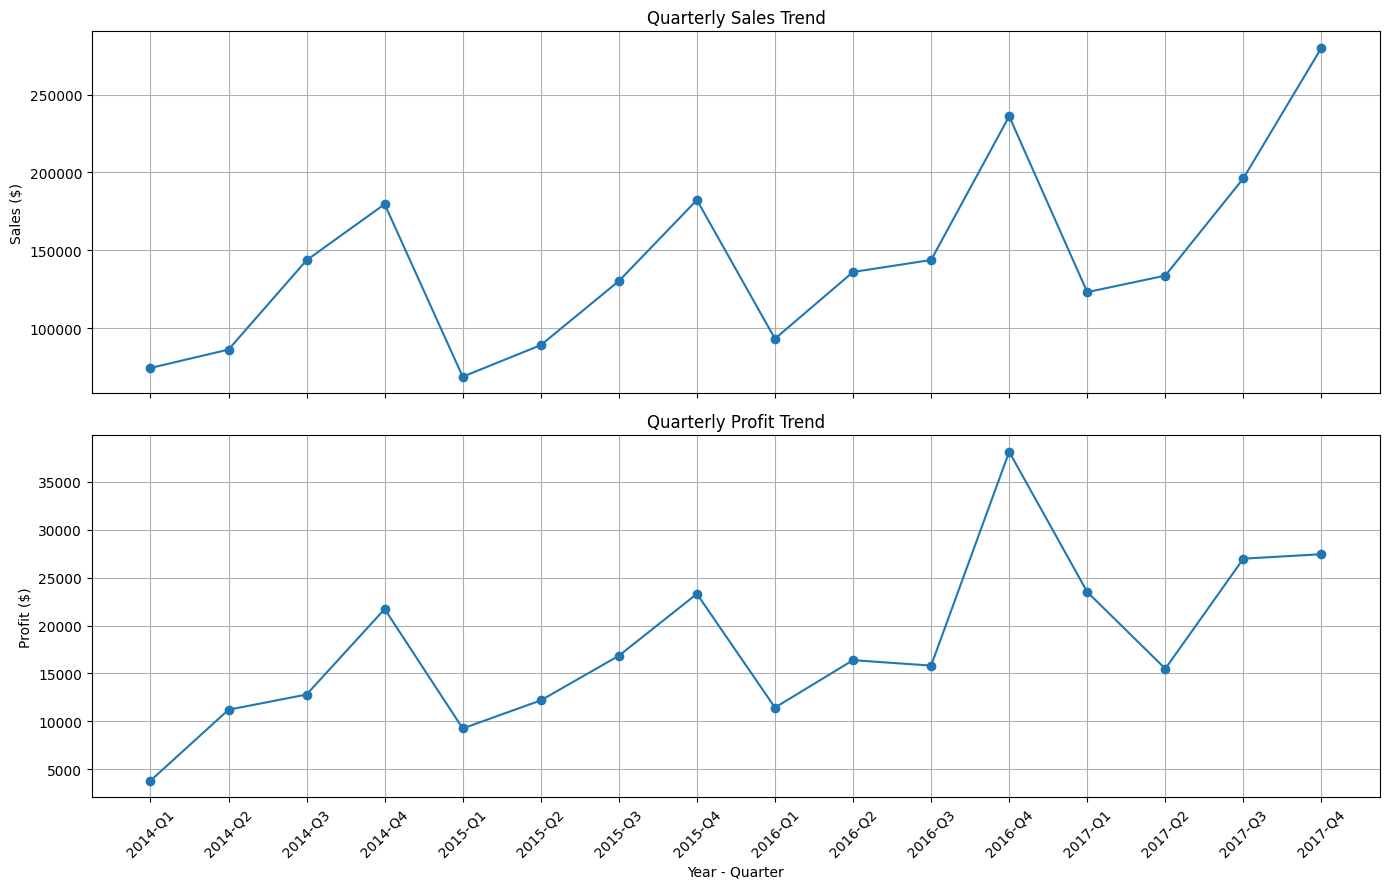

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(quarterly_trend['year_quarter'], quarterly_trend['total_sales'], marker='o')
axes[0].set_title('Quarterly Sales Trend')
axes[0].set_ylabel('Sales ($)')
axes[0].grid(True)

axes[1].plot(quarterly_trend['year_quarter'], quarterly_trend['total_profit'], marker='o')
axes[1].set_title('Quarterly Profit Trend')
axes[1].set_ylabel('Profit ($)')
axes[1].set_xlabel('Year - Quarter')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [10]:
quarterly_seasonality = quarterly_trend.groupby('quarter').agg(
    avg_sales=('total_sales', 'mean'),
    avg_profit=('total_profit', 'mean')
).reset_index()

quarterly_seasonality['quarter_name'] = 'Q' + quarterly_seasonality['quarter'].astype(str)

display(quarterly_seasonality.round(2))

,quarter,avg_sales,avg_profit,quarter_name
0,1,89920.39,12005.94,Q1
1,2,111307.06,13824.15,Q2
2,3,153483.03,18116.77,Q3
3,4,219519.39,27655.41,Q4


In [11]:
quarterly_trend['margin_%'] = quarterly_trend['total_profit'] / quarterly_trend['total_sales'] * 100
display(quarterly_trend[['year_quarter', 'total_sales', 'total_profit', 'margin_%']].round(2))

,year_quarter,total_sales,total_profit,margin_%
0,2014-Q1,74447.80,3811.23,5.12
1,2014-Q2,86257.39,11216.13,13.00
2,2014-Q3,143633.21,12804.72,8.91
3,2014-Q4,179627.73,21723.95,12.09
4,2015-Q1,68851.74,9264.94,13.46
5,2015-Q2,89124.19,12190.92,13.68
6,2015-Q3,130259.58,16853.62,12.94
7,2015-Q4,182297.01,23309.12,12.79
8,2016-Q1,93237.18,11441.37,12.27
9,2016-Q2,136082.30,16390.34,12.04


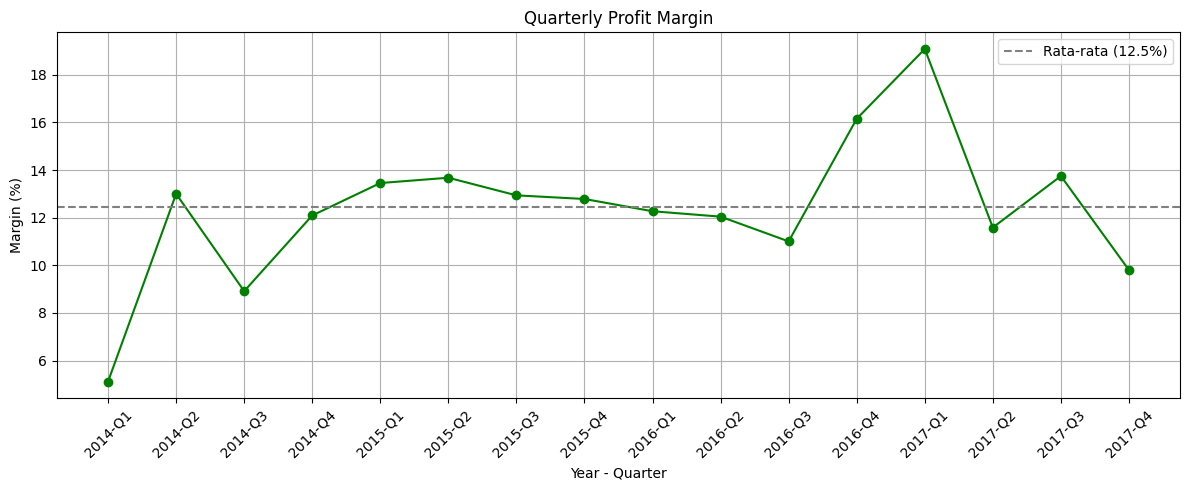

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(quarterly_trend['year_quarter'], quarterly_trend['margin_%'], marker='o', color='green')
plt.axhline(profit_margin, linestyle='--', color='gray', label=f'Rata-rata ({profit_margin:.1f}%)')
plt.title('Quarterly Profit Margin')
plt.xlabel('Year - Quarter'); plt.ylabel('Margin (%)')
plt.xticks(rotation=45); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

Kuartal 4 adalah kuartal dengan sales tertinggi di keempat tahun (rata-rata 219.519), dan Kuartal 1 yang terendah (89.920). Pada Q4 2017, sales naik ±18,6% dibanding Q4 2016, tetapi profit turun ±28% dan margin jatuh dari ±16,2% ke ±9,8%.

**Visualisasi Trend Bulanan**

In [13]:
monthly_trend = df.groupby('year_month').agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

monthly_trend['year_month'] = monthly_trend['year_month'].astype(str)

In [14]:
display(monthly_trend[monthly_trend['total_profit'] < 0])
display(monthly_trend.loc[[monthly_trend['total_profit'].idxmax()]])

,year_month,total_sales,total_profit
6,2014-07,33946.3930,-841.4826
12,2015-01,18174.0756,-3281.0070


,year_month,total_sales,total_profit
35,2016-12,96999.043,17885.3093


**Temuan tren bulanan:** Sales bulanan berfluktuasi tajam dengan tren naik jangka panjang, sedangkan profit bergerak di kisaran rendah dan relatif datar. Hanya dua bulan yang mencatat profit negatif: Juli 2014 (−841) dan Januari 2015 (−3.281). Profit bulanan tertinggi terjadi pada Desember 2016 (17.885), sementara sales tertinggi terjadi pada November 2017. Bulan dengan sales tertinggi tidak otomatis menjadi bulan dengan profit tertinggi.

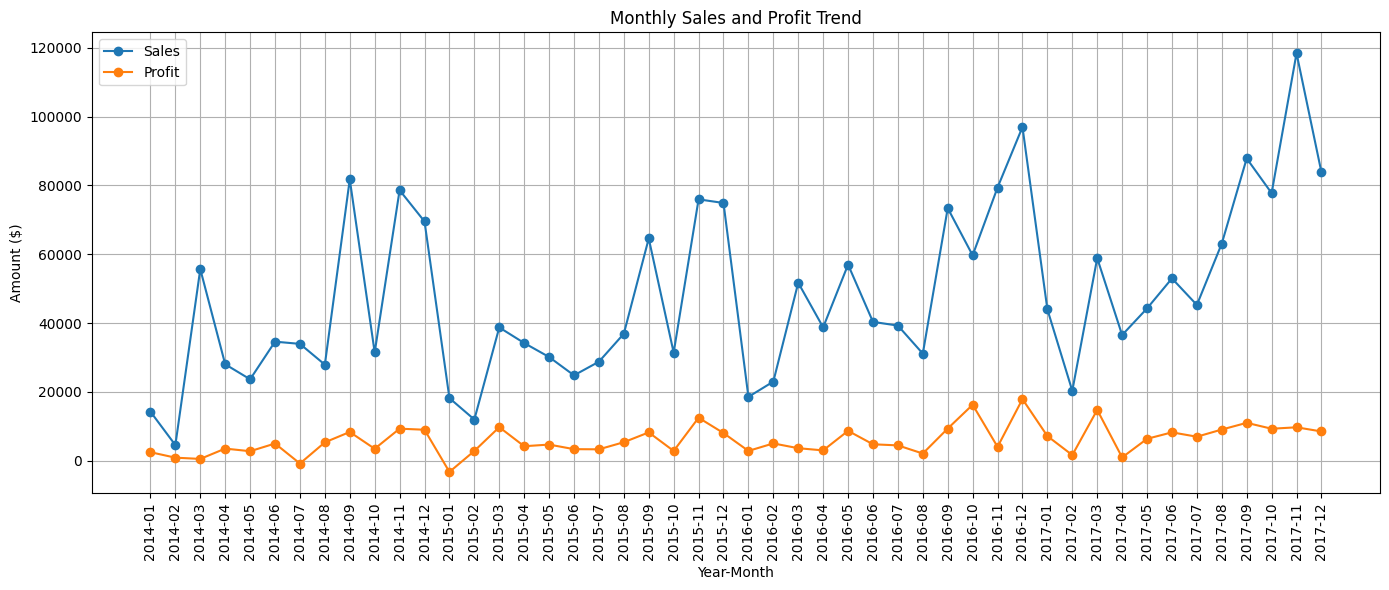

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_trend['year_month'],
    monthly_trend['total_sales'],
    label='Sales',
    marker='o'
)

plt.plot(
    monthly_trend['year_month'],
    monthly_trend['total_profit'],
    label='Profit',
    marker='o'
)

plt.title('Monthly Sales and Profit Trend')
plt.xlabel('Year-Month')
plt.ylabel('Amount ($)')
plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
monthly_seasonality = df.groupby(['year', 'month']).agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

seasonality = monthly_seasonality.groupby('month').agg(
    avg_sales=('total_sales', 'mean'),
    avg_profit=('total_profit', 'mean')
).reset_index()

month_names = {
    1: 'January', 2: 'February', 3: 'March',
    4: 'April', 5: 'May', 6: 'June',
    7: 'July', 8: 'August', 9: 'September',
    10: 'October', 11: 'November', 12: 'December'
}

seasonality['month_name'] = seasonality['month'].map(month_names)

display(seasonality.round(2))

,month,avg_sales,avg_profit,month_name
0,1,23731.21,2283.61,January
1,2,14937.81,2573.65,February
2,3,51251.37,7148.67,March
3,4,34370.19,2899.87,April
4,5,38757.20,5602.83,May
5,6,38179.67,5321.45,June
6,7,36809.52,3458.17,July
7,8,39761.02,5444.23,August
8,9,76912.49,9214.37,September
9,10,50080.75,7946.01,October


,month_name,avg_sales,avg_profit,avg_margin_%
0,January,23731.21,2283.61,9.62
1,February,14937.81,2573.65,17.23
2,March,51251.37,7148.67,13.95
3,April,34370.19,2899.87,8.44
4,May,38757.20,5602.83,14.46
5,June,38179.67,5321.45,13.94
6,July,36809.52,3458.17,9.39
7,August,39761.02,5444.23,13.69
8,September,76912.49,9214.37,11.98
9,October,50080.75,7946.01,15.87


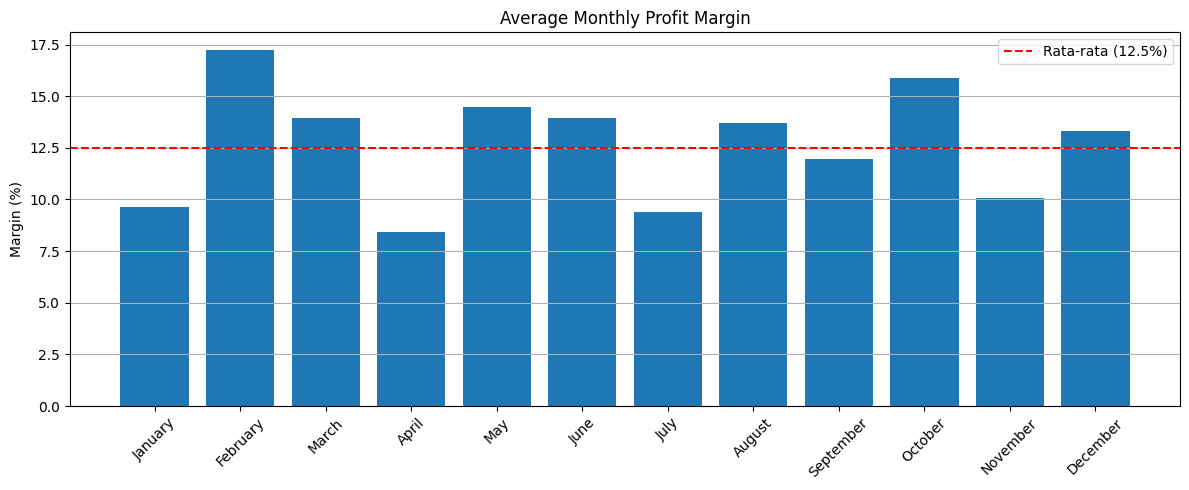

In [17]:
seasonality['avg_margin_%'] = seasonality['avg_profit'] / seasonality['avg_sales'] * 100
display(seasonality[['month_name', 'avg_sales', 'avg_profit', 'avg_margin_%']].round(2))

plt.figure(figsize=(12, 5))
plt.bar(seasonality['month_name'], seasonality['avg_margin_%'])
plt.axhline(profit_margin, linestyle='--', color='red', label=f'Rata-rata ({profit_margin:.1f}%)')
plt.title('Average Monthly Profit Margin'); plt.ylabel('Margin (%)')
plt.xticks(rotation=45); plt.legend(); plt.grid(axis='y')
plt.tight_layout(); plt.show()

In [18]:
highest_sales_month = seasonality.loc[seasonality['avg_sales'].idxmax()]
lowest_sales_month = seasonality.loc[seasonality['avg_sales'].idxmin()]
highest_profit_month = seasonality.loc[seasonality['avg_profit'].idxmax()]
lowest_profit_month = seasonality.loc[seasonality['avg_profit'].idxmin()]

print('Sales tertinggi:', highest_sales_month['month_name'], round(highest_sales_month['avg_sales'], 2))
print('Sales terendah:', lowest_sales_month['month_name'], round(lowest_sales_month['avg_sales'], 2))
print('Profit tertinggi:', highest_profit_month['month_name'], round(highest_profit_month['avg_profit'], 2))
print('Profit terendah:', lowest_profit_month['month_name'], round(lowest_profit_month['avg_profit'], 2))

Sales tertinggi: November 88115.27
Sales terendah: February 14937.81
Profit tertinggi: December 10842.3
Profit terendah: January 2283.61


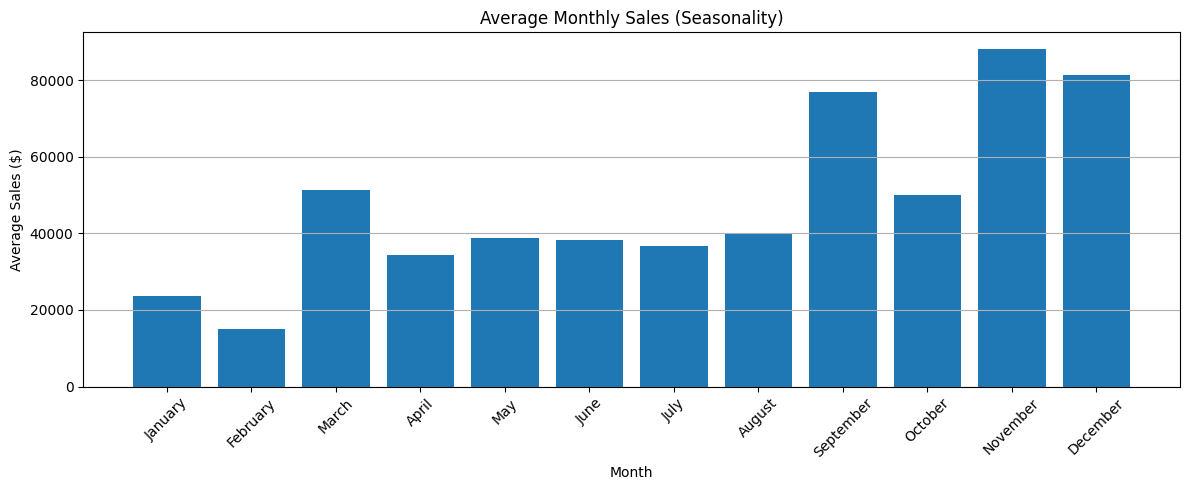

In [19]:
plt.figure(figsize=(12, 5))

plt.bar(seasonality['month_name'], seasonality['avg_sales'])

plt.title('Average Monthly Sales (Seasonality)')
plt.xlabel('Month')
plt.ylabel('Average Sales ($)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

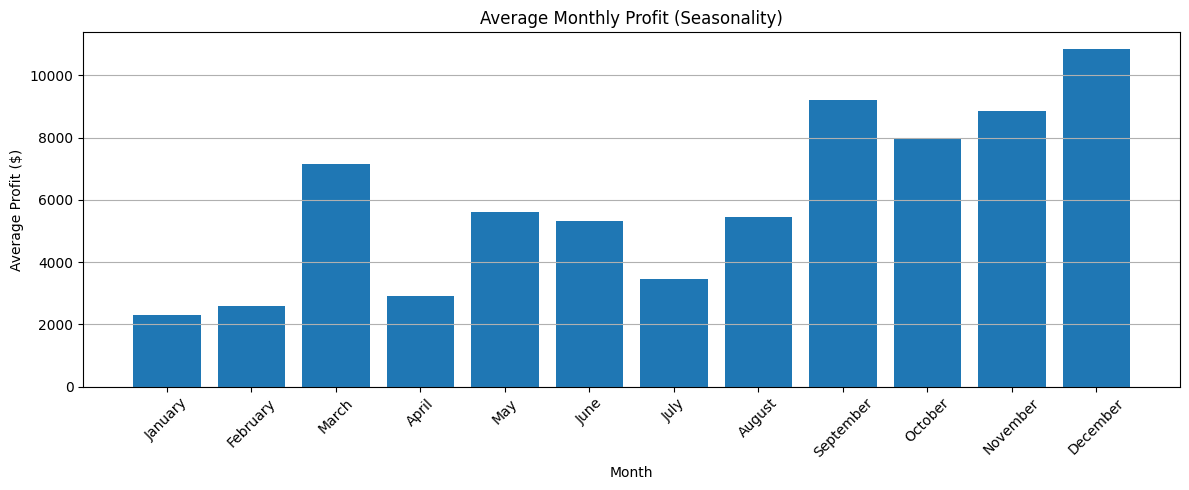

In [20]:
plt.figure(figsize=(12, 5))

plt.bar(seasonality['month_name'], seasonality['avg_profit'])

plt.title('Average Monthly Profit (Seasonality)')
plt.xlabel('Month')
plt.ylabel('Average Profit ($)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

Sales rata-rata tertinggi di November (88.115) dan terendah di Februari (14.938). Profit rata-rata tertinggi di Desember (10.842) dan terendah di Januari (2.284). September, November, dan Desember konsisten menjadi bulan ramai.

### Kinerja kategori dan sub-kategori

In [21]:
subcat = (df.groupby(['category','sub_category'])
            .agg(sales=('sales','sum'), profit=('profit','sum'))
            .reset_index())
subcat['margin%']= (subcat['profit'] / subcat['sales']) * 100
subcat['profit_share_%'] = ( subcat['profit'] / df['profit'].sum()) * 100
subcat = subcat.sort_values('profit')

display(subcat.round(2))

,category,sub_category,sales,profit,margin%,profit_share_%
3,Furniture,Tables,206965.53,-17725.48,-8.56,-6.19
0,Furniture,Bookcases,114880.00,-3472.56,-3.02,-1.21
12,Office Supplies,Supplies,46673.54,-1189.10,-2.55,-0.42
8,Office Supplies,Fasteners,3024.28,949.52,31.40,0.33
15,Technology,Machines,189238.63,3384.76,1.79,1.18
9,Office Supplies,Labels,12486.31,5546.25,44.42,1.94
5,Office Supplies,Art,27118.79,6527.79,24.07,2.28
7,Office Supplies,Envelopes,16476.40,6964.18,42.27,2.43
2,Furniture,Furnishings,91705.16,13059.14,14.24,4.56
4,Office Supplies,Appliances,107532.16,18138.01,16.87,6.33


### Insight – Kinerja Kategori dan Sub-Kategori

Berdasarkan hasil analisis terhadap 17 sub-kategori produk, ditemukan bahwa terdapat tiga sub-kategori yang mengalami kerugian, yaitu Tables, Bookcases, dan Supplies. Tables menjadi sub-kategori dengan kerugian terbesar sebesar $17,725.48, dengan profit margin sebesar -8.56%.

Selain itu, ditemukan beberapa sub-kategori dengan nilai penjualan tinggi tetapi memiliki profit margin yang relatif rendah. Contohnya adalah Machines dengan sales sebesar $189,238.63, tetapi hanya menghasilkan margin sebesar 1.79%. Hal ini menunjukkan bahwa tingginya nilai penjualan tidak selalu diikuti oleh tingkat keuntungan yang tinggi.

Di sisi lain, Copiers menjadi sub-kategori dengan total profit terbesar, yaitu $55,617.82, atau berkontribusi sekitar 19.42% terhadap total profit perusahaan.

**Business Insight:** Perusahaan perlu mengevaluasi strategi penjualan pada sub-kategori yang mengalami kerugian, khususnya Tables. Selain itu, sub-kategori seperti Machines, Chairs, dan Storage perlu dianalisis lebih lanjut untuk mengetahui faktor yang menyebabkan profit margin relatif rendah. Analisis diskon pada tahap berikutnya dapat membantu menguji apakah pemberian diskon berkaitan dengan rendahnya profitabilitas produk.

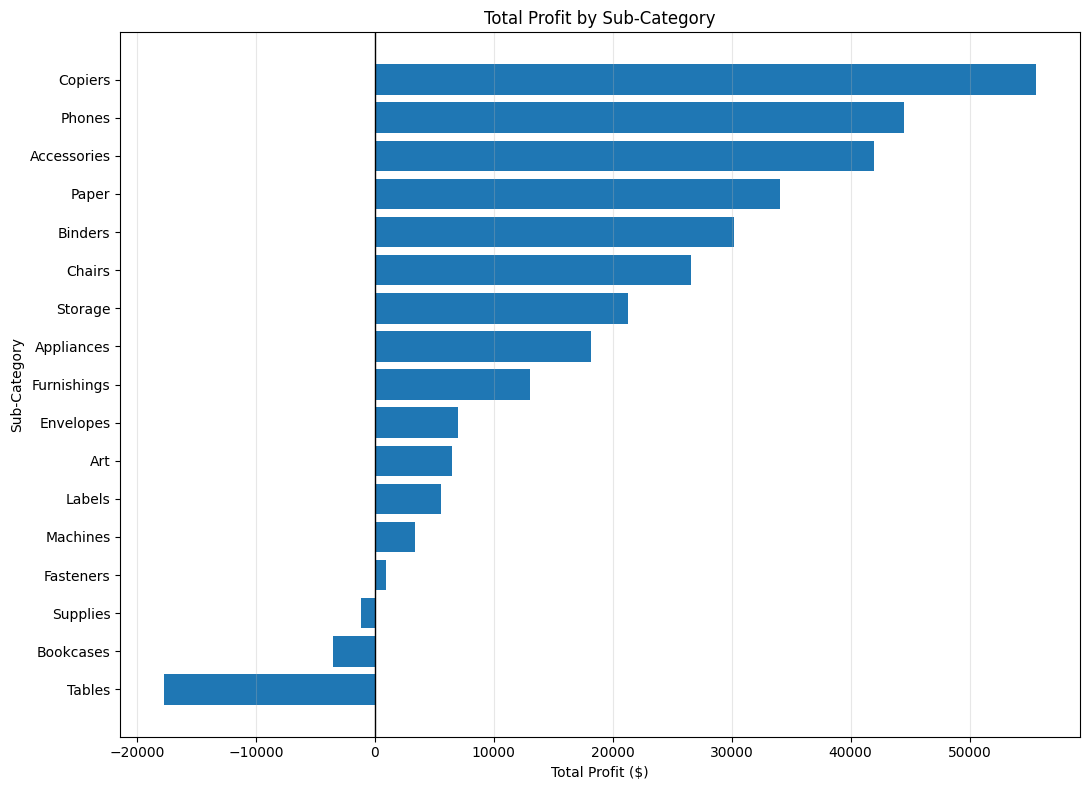

In [22]:
plt.figure(figsize=(11, 8))

plt.barh(
    subcat['sub_category'],
    subcat['profit']
)

plt.axvline(0, color='black', linewidth=1)

plt.title('Total Profit by Sub-Category')
plt.xlabel('Total Profit ($)')
plt.ylabel('Sub-Category')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Diskon vs Profit

**Tujuan**

Menganalisis hubungan antara tingkat pemberian diskon dengan profitabilitas perusahaan berdasarkan kelompok diskon.

**Metode**

Data diskon dikelompokkan menjadi empat kategori, yaitu 0%, 1–20%, 21–40%, dan lebih dari 40%. Selanjutnya, dilakukan agregasi total sales, total profit, dan perhitungan profit margin pada setiap kelompok.

In [23]:
df['discount_band'] = pd.cut(
    df['discount'],
    bins=[-0.01, 0, 0.2, 0.4, 1.0],
    labels=['0%', '1-20%', '21-40%', '>40%']
)

In [24]:
band = df.groupby(
    'discount_band',
    observed=True
).agg(
    rows=('sales', 'size'),
    sales=('sales', 'sum'),
    profit=('profit', 'sum')
).reset_index()

band['margin_%'] = (
    band['profit'] / band['sales']
) * 100

display(band.round(2))

,discount_band,rows,sales,profit,margin_%
0,0%,4798,1087908.47,320987.60,29.51
1,1-20%,3803,846522.24,100785.47,11.91
2,21-40%,459,233856.53,-35805.41,-15.31
3,>40%,933,128632.25,-99558.59,-77.40


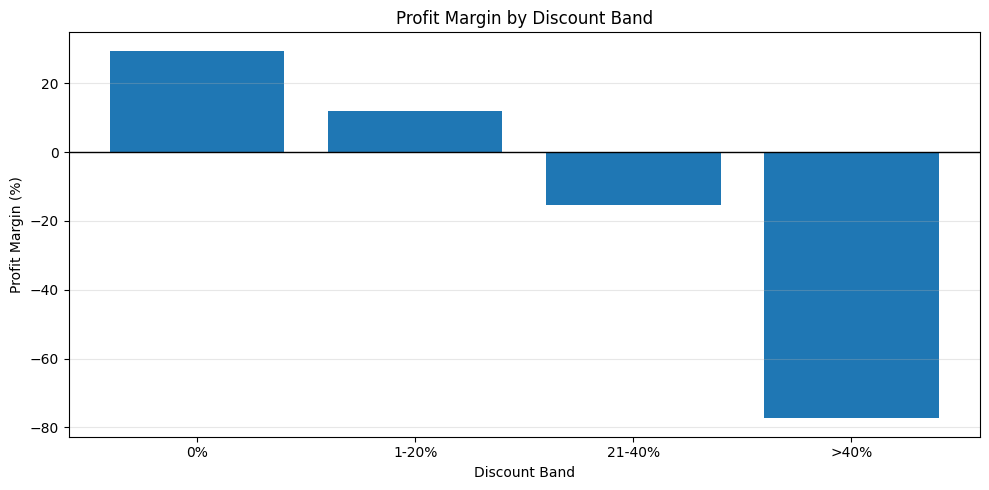

In [25]:
plt.figure(figsize=(10, 5))

plt.bar(
    band['discount_band'].astype(str),
    band['margin_%']
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Profit Margin by Discount Band')
plt.xlabel('Discount Band')
plt.ylabel('Profit Margin (%)')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Insight – Hubungan Diskon terhadap Profit

Berdasarkan hasil analisis pengelompokan diskon, ditemukan adanya pola penurunan profit margin seiring meningkatnya tingkat diskon yang diberikan perusahaan.

Transaksi tanpa diskon menghasilkan profit margin tertinggi sebesar 29,51%, sedangkan kelompok diskon 1–20% menghasilkan margin sebesar 11,91%. Pada kelompok diskon 21–40%, profit margin mulai bernilai negatif sebesar -15,31%, dengan total kerugian sebesar $35.805,41.

Kondisi yang lebih signifikan ditemukan pada kelompok diskon di atas 40%, yang menghasilkan profit margin sebesar -77,40% dan total kerugian sebesar $99.558,59.

**Business Insight:** Hasil analisis menunjukkan bahwa transaksi dengan tingkat diskon yang lebih tinggi memiliki profitabilitas yang lebih rendah. Perusahaan perlu mengevaluasi kebijakan pemberian diskon, terutama pada tingkat diskon di atas 20%, untuk mengurangi risiko kerugian dan menjaga profit margin.

Temuan ini menunjukkan adanya hubungan antara tingkat diskon dan profitabilitas, tetapi belum membuktikan bahwa diskon merupakan satu-satunya penyebab kerugian.

### Uji Hipotesis Q4 2017

In [26]:
q4 = df[df['quarter'] == 4].copy()

In [27]:
q4_analysis = q4.groupby('year').agg(
    avg_discount=('discount', 'mean'),
    pct_rows_discounted=(
        'discount',
        lambda s: (s > 0).mean() * 100
    ),
    sales=('sales', 'sum'),
    profit=('profit', 'sum'),
    total_rows=('sales', 'size')
).reset_index()

q4_analysis['margin_%'] = (
    q4_analysis['profit'] / q4_analysis['sales']
) * 100

display(q4_analysis.round(2))

,year,avg_discount,pct_rows_discounted,sales,profit,total_rows,margin_%
0,2014,0.17,55.89,179627.73,21723.95,755,12.09
1,2015,0.15,50.99,182297.01,23309.12,806,12.79
2,2016,0.15,50.54,236098.75,38139.86,918,16.15
3,2017,0.16,52.91,280054.07,27448.73,1219,9.80


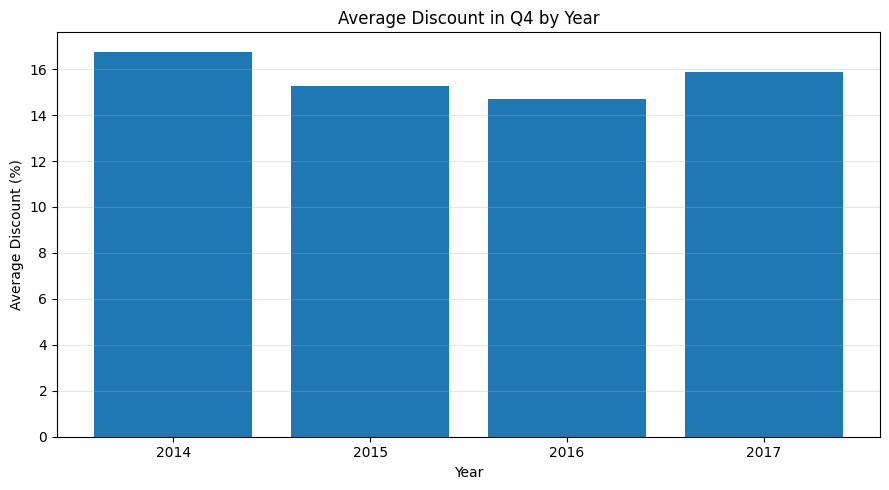

In [28]:
plt.figure(figsize=(9, 5))

plt.bar(
    q4_analysis['year'].astype(str),
    q4_analysis['avg_discount'] * 100
)

plt.title('Average Discount in Q4 by Year')
plt.xlabel('Year')
plt.ylabel('Average Discount (%)')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

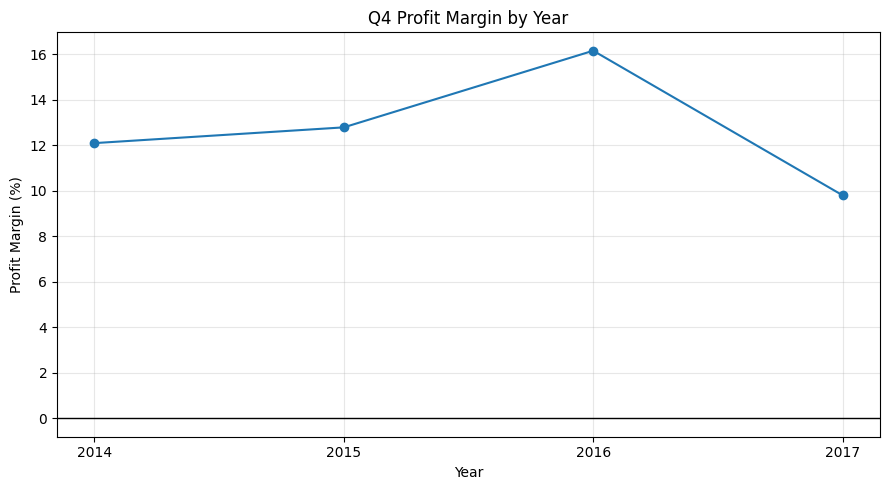

In [29]:
plt.figure(figsize=(9, 5))

plt.plot(
    q4_analysis['year'].astype(str),
    q4_analysis['margin_%'],
    marker='o'
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Q4 Profit Margin by Year')
plt.xlabel('Year')
plt.ylabel('Profit Margin (%)')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
comparison = q4_analysis.set_index('year')

q4_comparison = comparison.loc[
    [2016, 2017],
    ['avg_discount', 'pct_rows_discounted', 'sales', 'profit', 'margin_%']
]

display(q4_comparison.round(2))

,avg_discount,pct_rows_discounted,sales,profit,margin_%
year,,,,,
2016,0.15,50.54,236098.75,38139.86,16.15
2017,0.16,52.91,280054.07,27448.73,9.80


In [31]:
sales_growth = (
    (comparison.loc[2017, 'sales'] /
     comparison.loc[2016, 'sales']) - 1
) * 100

profit_growth = (
    (comparison.loc[2017, 'profit'] /
     comparison.loc[2016, 'profit']) - 1
) * 100

discount_change = (
    comparison.loc[2017, 'avg_discount'] -
    comparison.loc[2016, 'avg_discount']
) * 100

margin_change = (
    comparison.loc[2017, 'margin_%'] -
    comparison.loc[2016, 'margin_%']
)

print(f"Sales Growth: {sales_growth:.2f}%")
print(f"Profit Growth: {profit_growth:.2f}%")
print(f"Perubahan rata-rata diskon: {discount_change:.2f} poin persentase")
print(f"Perubahan margin: {margin_change:.2f} poin persentase")

Sales Growth: 18.62%
Profit Growth: -28.03%
Perubahan rata-rata diskon: 1.19 poin persentase
Perubahan margin: -6.35 poin persentase


### Insight – Pengujian Hipotesis Q4 2017

Berdasarkan hasil perbandingan kuartal keempat (Q4) pada tahun 2014 hingga 2017, ditemukan adanya penurunan profit margin yang cukup signifikan pada tahun 2017.

Rata-rata diskon Q4 2017 hanya naik 1,19 poin persentase dan masih lebih rendah daripada Q4 2014 (yang margin-nya 12,09%). Perubahan sekecil itu tidak cukup menjelaskan penurunan margin 6,35 poin persentase, sehingga rata-rata diskon bukan penjelas utama. Penyebab yang lebih mungkin ada pada komposisi transaksi, misalnya porsi transaksi diskon tinggi (>20%) atau sub-kategori yang merugi.

Pada periode yang sama, rata-rata diskon meningkat dari sekitar 15% menjadi 16%, sedangkan persentase transaksi yang mendapatkan diskon meningkat dari 50.54% menjadi 52.91%.

Jika dibandingkan dengan seluruh periode Q4, rata-rata diskon tahun 2017 bukan yang tertinggi karena Q4 2014 memiliki rata-rata diskon sekitar 17%. Meskipun demikian, Q4 2017 mencatat profit margin terendah di antara keempat Q4. Margin kuartalan secara keseluruhan lebih rendah di 2014-Q1 (5,12%) dan 2014-Q3 (8,91%).

**Kesimpulan:** Hasil analisis deskriptif menunjukkan bahwa peningkatan pemberian diskon pada Q4 2017 terjadi bersamaan dengan penurunan profit margin. Temuan ini mendukung dugaan adanya hubungan antara kebijakan diskon dan penurunan profitabilitas. Namun, analisis ini belum membuktikan bahwa diskon merupakan penyebab langsung penurunan profit karena faktor lain, seperti komposisi produk yang dijual dan karakteristik transaksi, juga dapat memengaruhi profitabilitas.

## Pengujian Lanjutan Q4 2017: Komposisi Transaksi
Pada pengujian di atas, rata-rata diskon Q4 2017 (15,9%) hanya naik sedikit dari Q4 2016 (14,7%), dan Q4 2014 punya diskon lebih tinggi (16,8%) dengan margin yang lebih baik. Jadi **rata-rata diskon bukan penjelas utama**. Hipotesis baru: yang berubah adalah **komposisi transaksi**, yaitu porsi penjualan dengan diskon dalam (>20%) dan sub-kategori yang merugi.

In [32]:
q4 = df[df['quarter'] == 4].copy()
q4['diskon_tinggi'] = q4['discount'] > 0.2

ringkas = q4.groupby('year').agg(
    sales=('sales', 'sum'), profit=('profit', 'sum'), avg_discount=('discount', 'mean'),
    share_baris_diskon_tinggi=('diskon_tinggi', 'mean'))
ringkas['margin_%'] = ringkas['profit'] / ringkas['sales'] * 100
ringkas['avg_discount'] *= 100
ringkas['share_baris_diskon_tinggi'] *= 100
ringkas['sales_diskon_tinggi'] = q4[q4['diskon_tinggi']].groupby('year')['sales'].sum()
ringkas['profit_diskon_tinggi'] = q4[q4['diskon_tinggi']].groupby('year')['profit'].sum()
display(ringkas.round(2))

d_profit = ringkas.loc[2017, 'profit'] - ringkas.loc[2016, 'profit']
d_tinggi = ringkas.loc[2017, 'profit_diskon_tinggi'] - ringkas.loc[2016, 'profit_diskon_tinggi']
print(f'Perubahan profit Q4 2016 -> 2017: {d_profit:,.2f}')
print(f'  dari transaksi diskon >20%    : {d_tinggi:,.2f} ({d_tinggi / d_profit:.1%} dari penurunan)')
print(f'Pertumbuhan sales transaksi diskon >20%: {ringkas.loc[2017, "sales_diskon_tinggi"] / ringkas.loc[2016, "sales_diskon_tinggi"] - 1:.1%}')
print(f'Pertumbuhan sales total               : {ringkas.loc[2017, "sales"] / ringkas.loc[2016, "sales"] - 1:.1%}')

,sales,profit,avg_discount,share_baris_diskon_tinggi,margin_%,sales_diskon_tinggi,profit_diskon_tinggi
year,,,,,,,
2014,179627.73,21723.95,16.76,14.70,12.09,24824.21,-8000.08
2015,182297.01,23309.12,15.25,12.90,12.79,24255.30,-11599.57
2016,236098.75,38139.86,14.69,12.85,16.15,29706.07,-14681.72
2017,280054.07,27448.73,15.88,14.27,9.80,48242.38,-24209.59


Perubahan profit Q4 2016 -> 2017: -10,691.13
  dari transaksi diskon >20%    : -9,527.87 (89.1% dari penurunan)
Pertumbuhan sales transaksi diskon >20%: 62.4%
Pertumbuhan sales total               : 18.6%


In [33]:
per_sub_q4 = q4.groupby(['sub_category', 'year'])['profit'].sum().unstack('year').round(0)
per_sub_q4['selisih_2017_vs_2016'] = per_sub_q4[2017] - per_sub_q4[2016]
print('Profit Q4 per sub-kategori (urut dari penurunan terbesar):')
display(per_sub_q4.sort_values('selisih_2017_vs_2016').head(6))

print('\nTransaksi dengan profit terbesar di Q4 2016 (pembanding):')
display(q4[q4['year'] == 2016].nlargest(4, 'profit')[['order_date', 'sub_category', 'product_name', 'sales', 'discount', 'profit']].round(2))
print('\nTransaksi dengan kerugian terbesar di Q4 2017:')
display(q4[q4['year'] == 2017].nsmallest(5, 'profit')[['order_date', 'state', 'sub_category', 'product_name', 'sales', 'discount', 'profit']].round(2))

Profit Q4 per sub-kategori (urut dari penurunan terbesar):


year,2014,2015,2016,2017,selisih_2017_vs_2016
sub_category,,,,,
Binders,-375.0,-1285.0,10489.0,-2199.0,-12688.0
Tables,-1002.0,-386.0,-1552.0,-4530.0,-2978.0
Bookcases,25.0,-168.0,18.0,-894.0,-912.0
Appliances,1431.0,2380.0,3064.0,2467.0,-597.0
Furnishings,332.0,810.0,2156.0,1578.0,-578.0
Copiers,861.0,4229.0,12162.0,11888.0,-274.0



Transaksi dengan profit terbesar di Q4 2016 (pembanding):


,order_date,sub_category,product_name,sales,discount,profit
6825,2016-10-02,Copiers,Canon imageCLASS 2200 Advanced Copier,17499.95,0.0,8399.98
9038,2016-12-17,Binders,GBC Ibimaster 500 Manual ProClick Binding System,9892.74,0.0,4946.37
7665,2016-10-04,Copiers,Hewlett Packard LaserJet 3310 Copier,5399.91,0.0,2591.96
7817,2016-10-21,Binders,Ibico EPK-21 Electric Binding System,4535.98,0.2,1644.29



Transaksi dengan kerugian terbesar di Q4 2017:


,order_date,state,sub_category,product_name,sales,discount,profit
683,2017-11-04,North Carolina,Machines,Cubify CubeX 3D Printer Triple Head Print,7999.98,0.5,-3839.99
4990,2017-12-07,Illinois,Binders,Ibico EPK-21 Electric Binding System,1889.99,0.8,-2929.48
5309,2017-11-19,Texas,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.19,0.8,-2287.78
2928,2017-10-19,North Carolina,Binders,GBC DocuBind P400 Electric Binding System,1633.19,0.7,-1306.55
5319,2017-10-02,Tennessee,Tables,Chromcraft Bull-Nose Wood Oval Conference Tabl...,2314.12,0.4,-1002.78


In [34]:
def performa(kolom, data=df):
    t = (data.groupby(kolom)
             .agg(sales=('sales', 'sum'),
                  profit=('profit', 'sum'),
                  orders=('order_id', 'nunique'),
                  avg_discount=('discount', 'mean'))
             .reset_index())
    t['margin_%'] = t['profit'] / t['sales'] * 100
    t['aov'] = t['sales'] / t['orders']
    t['avg_discount'] = t['avg_discount'] * 100
    return t.sort_values('profit')

## Kategori dan sub-kategori 
Sub-kategori sudah dibahas di bagian sebelumnya. Di sini kita lengkapi dengan ringkasan **tiga kategori utama**.

,category,sales,profit,orders,avg_discount,margin_%,aov
0,Furniture,741718.42,18463.33,1764,17.39,2.49,420.48
1,Office Supplies,719047.03,122490.80,3742,15.73,17.04,192.16
2,Technology,836154.03,145454.95,1544,13.23,17.40,541.55


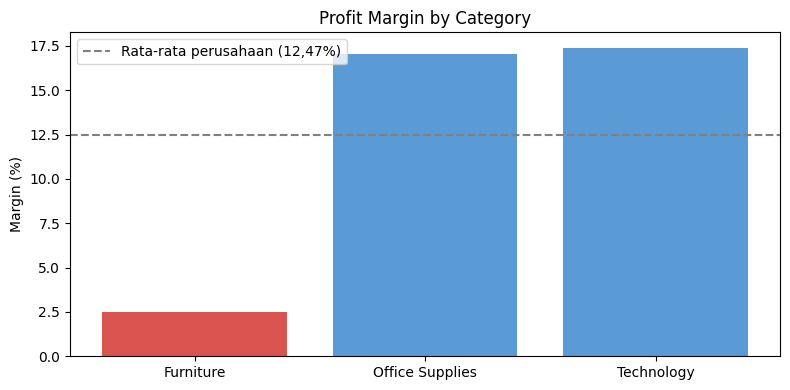

In [35]:
kategori = performa('category')
display(kategori.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(kategori['category'], kategori['margin_%'], color=['#d9534f', '#5b9bd5', '#5b9bd5'])
ax.axhline(total_profit / total_sales * 100, ls='--', color='gray', label='Rata-rata perusahaan (12,47%)')
ax.set_title('Profit Margin by Category'); ax.set_ylabel('Margin (%)'); ax.legend()
plt.tight_layout(); plt.show()

**Temuan:** Technology (17,40%) dan Office Supplies (17,04%) bermargin sehat, sedangkan **Furniture hanya 2,49%** meskipun sales-nya 741.718 (±32% dari total). Furniture menyumbang profit 18.463, hanya ±6% dari total profit. Penyebabnya terkonsentrasi di dua sub-kategori: Tables (−17.725) dan Bookcases (−3.473); Chairs dan Furnishings tetap untung (26.602 dan 13.059).

## Produk: sales tinggi tetapi profit negatif 
Berdasarkan keputusan di notebook cleaning, analisis tingkat produk memakai `product_name`.

In [36]:
produk = performa('product_name')

# profit dibulatkan 2 desimal: penjumlahan float bisa menghasilkan -1e-15 untuk produk yang sebenarnya impas
rugi_mask = produk['profit'].round(2) < 0
n_rugi = rugi_mask.sum()
print(f'Produk merugi: {n_rugi} dari {len(produk)} ({n_rugi / len(produk):.1%}) | total kerugian: {produk.loc[rugi_mask, "profit"].sum():,.2f}')

print('\n10 produk dengan profit paling negatif:')
display(produk.head(10).round(2))

# produk yang termasuk 10% sales teratas tetapi profitnya negatif
batas_sales = produk['sales'].quantile(0.9)
besar_rugi = produk[(produk['sales'] >= batas_sales) & rugi_mask].sort_values('sales', ascending=False)
print('\nProduk dengan sales di 10% teratas tetapi profit negatif:')
display(besar_rugi.head(10).round(2))

Produk merugi: 299 dari 1850 (16.2%) | total kerugian: -77,068.38

10 produk dengan profit paling negatif:


,product_name,sales,profit,orders,avg_discount,margin_%,aov
475,Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97,3,53.33,-80.00,3699.99
985,Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97,4,40.00,-27.27,4207.48
476,Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99,1,50.00,-48.00,7999.98
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.64,-2876.12,5,28.00,-29.00,1983.53
376,Bush Advantage Collection Racetrack Conference...,9544.72,-1934.40,7,35.00,-20.27,1363.53
683,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,6,45.00,-10.45,2994.18
444,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08,1,50.00,-8.00,22638.48
1043,Martin Yale Chadless Opener Electric Letter Op...,16656.20,-1299.18,6,10.00,-7.80,2776.03
285,Balt Solid Wood Round Tables,6518.75,-1201.06,4,20.00,-18.42,1629.69
364,BoxOffice By Design Rectangular and Half-Moon ...,1706.25,-1148.44,3,48.33,-67.31,568.75



Produk dengan sales di 10% teratas tetapi profit negatif:


,product_name,sales,profit,orders,avg_discount,margin_%,aov
444,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08,1,50.00,-8.00,22638.48
683,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,6,45.00,-10.45,2994.18
813,High Speed Automatic Electric Letter Opener,17030.31,-262.00,3,6.67,-1.54,5676.77
985,Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97,4,40.00,-27.27,4207.48
1043,Martin Yale Chadless Opener Electric Letter Op...,16656.20,-1299.18,6,10.00,-7.80,2776.03
1351,"Riverside Palais Royal Lawyers Bookcase, Royal...",15610.97,-669.54,5,23.40,-4.29,3122.19
368,Bretford Rectangular Conference Table Tops,12995.29,-327.23,12,24.58,-2.52,1082.94
475,Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97,3,53.33,-80.00,3699.99
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.64,-2876.12,5,28.00,-29.00,1983.53
376,Bush Advantage Collection Racetrack Conference...,9544.72,-1934.40,7,35.00,-20.27,1363.53


**Temuan:** 299 dari 1.850 produk (16,2%) merugi, dengan total kerugian ±77.068. (Dua produk lain memiliki profit −0,0000000000000018 dan −0,000000000000007; itu hanya artefak pembulatan angka desimal dan sebenarnya impas, jadi tidak dihitung rugi. Hasil ini sama dengan query SQL yang memakai tipe NUMERIC.) Kerugian terbesar ada pada produk bernilai tinggi dengan diskon besar, misalnya **Cubify CubeX 3D Printer Double Head** (−8.880, rata-rata diskon 53%) dan **Lexmark MX611dhe Laser Printer** (−4.590, diskon 40%). Di kelompok sales tertinggi, Cisco TelePresence System EX90 (sales 22.638, hanya 1 pesanan, diskon 50%) dan GBC DocuBind P400 (sales 17.965, diskon 45%) juga merugi. Pola ini mengarah pada **diskon dalam pada produk berharga tinggi**.

## Wilayah: region, state, kota 

In [37]:
region = performa('region')
display(region.round(2))

state = performa('state')
print('10 state dengan profit terendah:')
display(state.head(10).round(2))
print('5 state dengan profit tertinggi:')
display(state.tail(5).round(2))

rugi = state[state['profit'] < 0]
print(f'State merugi: {len(rugi)} dari {len(state)} | total kerugian: {rugi["profit"].sum():,.2f}')
print(f'Porsi sales state merugi: {rugi["sales"].sum() / total_sales:.1%}')
diskon_rugi = df[df['state'].isin(rugi['state'])]['discount'].mean()
diskon_lain = df[~df['state'].isin(rugi['state'])]['discount'].mean()
print(f'Rata-rata diskon: state merugi {diskon_rugi:.1%} vs state lain {diskon_lain:.1%}')

,region,sales,profit,orders,avg_discount,margin_%,aov
0,Central,501239.89,39706.36,1175,24.04,7.92,426.59
2,South,391721.90,46749.43,822,14.73,11.93,476.55
1,East,678499.87,91534.84,1401,14.53,13.49,484.30
3,West,725457.82,108418.45,1611,10.93,14.94,450.32


10 state dengan profit terendah:


,state,sales,profit,orders,avg_discount,margin_%,aov
41,Texas,170188.05,-25729.36,487,37.02,-15.12,349.46
33,Ohio,77976.76,-16959.32,236,32.50,-21.75,330.41
36,Pennsylvania,116511.91,-15559.96,288,32.86,-13.35,404.56
11,Illinois,80166.10,-12607.89,276,39.00,-15.73,290.46
31,North Carolina,55603.16,-7490.91,136,28.35,-13.47,408.85
4,Colorado,32108.12,-6527.86,79,31.65,-20.33,406.43
40,Tennessee,30661.87,-5341.69,91,29.13,-17.42,336.94
1,Arizona,35282.00,-3427.92,108,30.36,-9.72,326.69
8,Florida,89473.71,-3399.30,200,29.93,-3.80,447.37
35,Oregon,17431.15,-1190.47,56,28.87,-6.83,311.27


5 state dengan profit tertinggi:


,state,sales,profit,orders,avg_discount,margin_%,aov
44,Virginia,70636.72,18597.95,115,0.00,26.33,614.23
20,Michigan,76269.61,24463.19,117,0.71,32.07,651.88
45,Washington,138641.27,33402.65,256,6.40,24.09,541.57
30,New York,310876.27,74038.55,562,5.53,23.82,553.16
3,California,457687.63,76381.39,1021,7.28,16.69,448.27


State merugi: 10 dari 49 | total kerugian: -98,234.68
Porsi sales state merugi: 30.7%
Rata-rata diskon: state merugi 33.6% vs state lain 4.2%


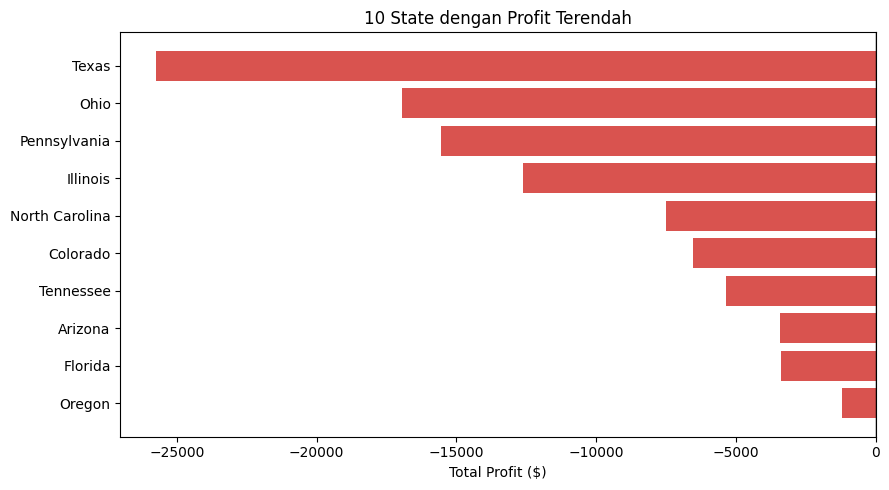

Kota merugi: 138 dari 604


,city,state,sales,profit,orders,avg_discount,margin_%,aov
430,Philadelphia,Pennsylvania,109077.01,-13837.77,265,32.68,-12.69,411.61
239,Houston,Texas,64504.76,-10153.55,188,37.97,-15.74,343.11
499,San Antonio,Texas,21843.53,-7299.05,27,38.31,-33.42,809.02
283,Lancaster,Ohio,8202.62,-7149.62,15,31.29,-87.16,546.84
90,Chicago,Illinois,48539.54,-6654.57,171,38.38,-13.71,283.86
69,Burlington,North Carolina,12681.28,-5894.53,7,30.91,-46.48,1811.61
313,Louisville,Colorado,5070.42,-3406.21,12,33.75,-67.18,422.53
126,Dallas,Texas,20131.93,-2846.53,80,35.86,-14.14,251.65


In [38]:
terburuk = state.head(10).sort_values('profit', ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(terburuk['state'], terburuk['profit'], color='#d9534f')
ax.axvline(0, color='black', lw=1)
ax.set_title('10 State dengan Profit Terendah'); ax.set_xlabel('Total Profit ($)')
plt.tight_layout(); plt.show()

kota = performa(['city', 'state'])
print(f'Kota merugi: {(kota["profit"] < 0).sum()} dari {len(kota)}')
display(kota.head(8).round(2))

**Temuan:** Region **Central** bermargin terendah (7,92%) dengan rata-rata diskon tertinggi (24%), sedangkan West terbaik (14,94%) dengan diskon terendah (±11%). Sepuluh dari 49 state merugi, total kerugian ±98.235 pada ±31% dari seluruh sales. State yang merugi mendapat rata-rata diskon **33,6%**, jauh di atas state lain (**4,2%**). Terbesar: **Texas (−25.729)**, **Ohio (−16.959)**, **Pennsylvania (−15.560)**, dan **Illinois (−12.608)**. Di tingkat kota, Philadelphia (−13.838) dan Houston (−10.154) paling merugi.

## Segmen pelanggan (Q6)

In [39]:
segmen = performa('segment')
segmen['share_sales_%'] = segmen['sales'] / total_sales * 100
display(segmen.round(2))

,segment,sales,profit,orders,avg_discount,margin_%,aov,share_sales_%
2,Home Office,429371.78,60310.74,909,14.70,14.05,472.36,18.69
1,Corporate,706146.37,91979.13,1514,15.82,13.03,466.41,30.74
0,Consumer,1161401.34,134119.21,2586,15.81,11.55,449.11,50.56


**Temuan:** Consumer mendominasi (sales 1.161.401, ±51% dari total) tetapi bermargin terendah (11,55%). Home Office memiliki margin tertinggi (14,05%) dan Corporate 13,03%. Selisih antar segmen tidak besar (±2,5 poin persentase) dan rata-rata diskon hampir sama (15-16%), sehingga **segmen bukan penggerak utama masalah profit**.

##  Pelanggan teratas dan ketergantungan bisnis 

In [40]:
pelanggan = (df.groupby(['customer_id', 'customer_name'])
               .agg(sales=('sales', 'sum'), profit=('profit', 'sum'), orders=('order_id', 'nunique'))
               .reset_index())

top_sales = pelanggan.sort_values('sales', ascending=False)
print('10 pelanggan dengan sales terbesar:')
display(top_sales.head(10).round(2))
print(f'Porsi 10 pelanggan teratas: {top_sales.head(10)["sales"].sum() / total_sales:.1%} dari sales, '
      f'{top_sales.head(10)["profit"].sum() / total_profit:.1%} dari profit')

# analisis Pareto: berapa pelanggan yang menghasilkan 80% sales?
top_sales = top_sales.reset_index(drop=True)
top_sales['cum_share'] = top_sales['sales'].cumsum() / total_sales
n80 = (top_sales['cum_share'] < 0.8).sum() + 1
print(f'Pelanggan yang menghasilkan 80% sales: {n80} dari {len(top_sales)} ({n80 / len(top_sales):.1%})')

rugi = pelanggan[pelanggan['profit'] < 0]
print(f'Pelanggan dengan total profit negatif: {len(rugi)} dari {len(pelanggan)} ({len(rugi) / len(pelanggan):.1%}) | total kerugian {rugi["profit"].sum():,.2f}')

10 pelanggan dengan sales terbesar:


,customer_id,customer_name,sales,profit,orders
700,SM-20320,Sean Miller,25043.05,-1980.74,5
741,TC-20980,Tamara Chand,19052.22,8981.32,5
621,RB-19360,Raymond Buch,15117.34,6976.10,6
730,TA-21385,Tom Ashbrook,14595.62,4703.79,4
6,AB-10105,Adrian Barton,14473.57,5444.81,10
434,KL-16645,Ken Lonsdale,14175.23,806.86,12
669,SC-20095,Sanjit Chand,14142.33,5757.41,9
327,HL-15040,Hunter Lopez,12873.30,5622.43,6
683,SE-20110,Sanjit Engle,12209.44,2650.68,11
131,CC-12370,Christopher Conant,12129.07,2177.05,5


Porsi 10 pelanggan teratas: 6.7% dari sales, 14.4% dari profit
Pelanggan yang menghasilkan 80% sales: 396 dari 793 (49.9%)
Pelanggan dengan total profit negatif: 155 dari 793 (19.5%) | total kerugian -71,212.42


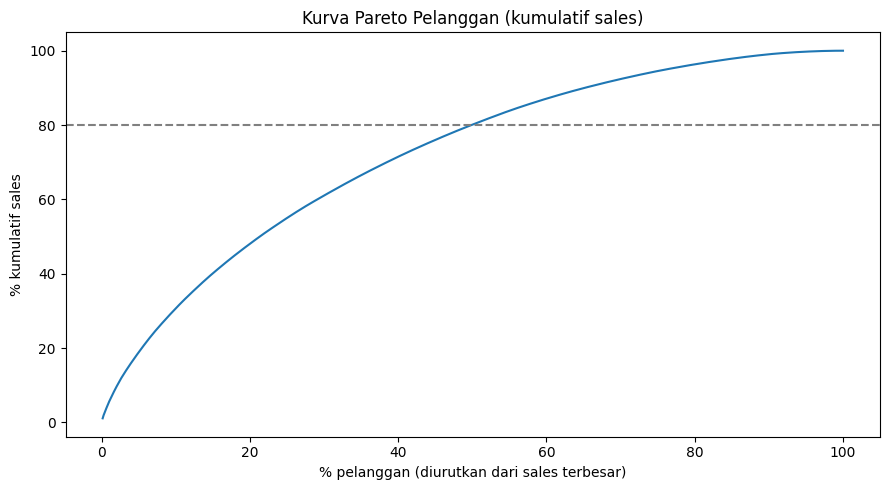

In [41]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot((top_sales.index + 1) / len(top_sales) * 100, top_sales['cum_share'] * 100)
ax.axhline(80, ls='--', color='gray')
ax.set_title('Kurva Pareto Pelanggan (kumulatif sales)')
ax.set_xlabel('% pelanggan (diurutkan dari sales terbesar)'); ax.set_ylabel('% kumulatif sales')
plt.tight_layout(); plt.show()

**Temuan:** Bisnis **tidak bergantung pada segelintir pelanggan**: 10 pelanggan teratas hanya menyumbang 6,7% sales (14,4% profit), dan dibutuhkan 396 dari 793 pelanggan (±50%) untuk mencapai 80% sales. Namun ada masalah profitabilitas di level pelanggan: **155 pelanggan (19,5%) total profitnya negatif** (total ±−71.212). Pelanggan dengan sales terbesar, Sean Miller (25.043), justru berprofit **−1.981**. Peringkat berdasarkan sales dan berdasarkan profit tidak sama, sehingga pelanggan sebaiknya dinilai dengan profit, bukan hanya sales.

## Diskon vs profit, lanjutan 
Sebelumnya kita melihat margin per kelompok diskon. Di sini kita (1) cari titik impas dengan kelompok yang lebih halus, (2) hitung kontribusi transaksi diskon tinggi, dan (3) hubungkan diskon dengan sub-kategori yang merugi.

,discount_fine,rows,sales,profit,margin_%
0,"(-0.01, 0.0]",4798,1087908.5,320987.6,29.5
1,"(0.0, 0.1]",94,54369.4,9029.2,16.6
2,"(0.1, 0.15]",52,27558.5,1419.0,5.1
3,"(0.15, 0.2]",3657,764594.4,90337.3,11.8
4,"(0.2, 0.3]",226,102945.3,-10357.2,-10.1
5,"(0.3, 0.4]",233,130911.2,-25448.2,-19.4
6,"(0.4, 0.5]",77,64403.5,-22999.5,-35.7
7,"(0.5, 0.6]",138,6644.7,-5944.7,-89.5
8,"(0.6, 0.7]",418,40620.3,-40075.4,-98.7
9,"(0.7, 0.8]",300,16963.8,-30539.0,-180.0


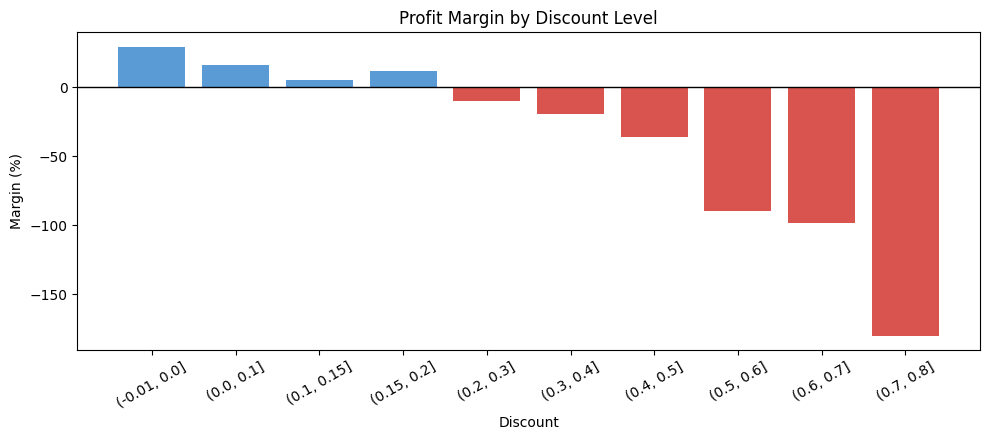

In [42]:
bins = [-0.01, 0, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
df['discount_fine'] = pd.cut(df['discount'], bins)
halus = (df.groupby('discount_fine', observed=True)
           .agg(rows=('sales', 'size'), sales=('sales', 'sum'), profit=('profit', 'sum'))
           .reset_index())
halus['margin_%'] = halus['profit'] / halus['sales'] * 100
display(halus.round(1))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(halus['discount_fine'].astype(str), halus['margin_%'],
       color=['#5b9bd5' if m > 0 else '#d9534f' for m in halus['margin_%']])
ax.axhline(0, color='black', lw=1)
ax.set_title('Profit Margin by Discount Level'); ax.set_xlabel('Discount'); ax.set_ylabel('Margin (%)')
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

In [43]:
tinggi = df[df['discount'] > 0.2]
rendah = df[df['discount'] <= 0.2]
print(f'Baris diskon >20%: {len(tinggi)} ({len(tinggi) / len(df):.1%} baris), {tinggi["sales"].sum() / total_sales:.1%} dari sales')
print(f'Profit dari baris diskon >20%: {tinggi["profit"].sum():,.2f} ({tinggi["profit"].sum() / total_profit:.1%} dari total profit)')
print(f'Margin baris diskon <=20%: {rendah["profit"].sum() / rendah["sales"].sum():.2%}')

Baris diskon >20%: 1392 (13.9% baris), 15.8% dari sales
Profit dari baris diskon >20%: -135,364.00 (-47.3% dari total profit)
Margin baris diskon <=20%: 21.80%


In [44]:
per_sub = (df.assign(diskon_tinggi=df['discount'] > 0.2)
             .groupby('sub_category')
             .agg(avg_discount=('discount', 'mean'),
                  pct_diskon_gt20=('diskon_tinggi', 'mean'),
                  sales=('sales', 'sum'), profit=('profit', 'sum'))
             .reset_index())
per_sub['avg_discount'] *= 100
per_sub['pct_diskon_gt20'] *= 100
per_sub['margin_%'] = per_sub['profit'] / per_sub['sales'] * 100
display(per_sub.sort_values('avg_discount', ascending=False).round(2))

,sub_category,avg_discount,pct_diskon_gt20,sales,profit,margin_%
3,Binders,37.23,40.25,203412.73,30221.76,14.86
11,Machines,30.61,46.09,189238.63,3384.76,1.79
16,Tables,26.13,55.17,206965.53,-17725.48,-8.56
4,Bookcases,21.11,30.70,114880.00,-3472.56,-3.02
5,Chairs,17.00,25.49,328167.73,26602.23,8.11
1,Appliances,16.65,14.38,107532.16,18138.01,16.87
6,Copiers,16.18,13.24,149528.03,55617.82,37.20
13,Phones,15.46,12.26,330007.05,44515.73,13.49
9,Furnishings,13.83,14.42,91705.16,13059.14,14.24
8,Fasteners,8.20,0.00,3024.28,949.52,31.40


**Temuan:**
- **Titik impas diskon ada di sekitar 20%.** Pada diskon 15-20% margin masih 12%, tetapi pada 20-30% sudah −10%, dan makin dalam makin parah (−180% pada diskon 70-80%).
- Transaksi diskon >20% hanya **13,9% dari baris** dan 15,8% dari sales, tetapi menghasilkan profit **−135.364**, setara −47% dari total profit bersih. Transaksi diskon ≤20% bermargin **21,8%**. (Ini bukan berarti menghilangkan seluruh transaksi tersebut otomatis menaikkan profit, karena volume penjualan ikut hilang.)
- **Tables** (rata-rata diskon 26,1%, 55% barisnya diskon >20%), **Machines** (30,6%, 46%), dan **Bookcases** (21,1%, 31%) adalah sub-kategori yang paling sering didiskon dalam dan margin-nya terendah. Pola ini mendukung penjelasan bahwa diskon menekan profit mereka.
- **Namun bukan satu-satunya penyebab.** Binders didiskon paling dalam (rata-rata 37,2%) tetapi tetap untung (margin 14,86%), dan **Supplies merugi tanpa ada diskon >20%** (rata-rata diskon hanya 7,7%). Supplies perlu dicek dari sisi harga atau biaya, bukan diskon.

## Mode pengiriman 

In [45]:
ship = performa('ship_mode')
ship['share_sales_%'] = ship['sales'] / total_sales * 100
display(ship.round(2))
print('Rata-rata durasi pengiriman per mode (hari):')
print(df.groupby('ship_mode')['shipping_duration'].mean().round(2).sort_values())

,ship_mode,sales,profit,orders,avg_discount,margin_%,aov,share_sales_%
1,Same Day,128363.12,15891.76,264,15.24,12.38,486.22,5.59
0,First Class,351428.42,48969.84,787,16.46,13.93,446.54,15.30
2,Second Class,459193.57,57446.64,964,13.89,12.51,476.34,19.99
3,Standard Class,1357934.37,164100.85,2994,16.00,12.08,453.55,59.12


Rata-rata durasi pengiriman per mode (hari):
ship_mode
Same Day          0.04
First Class       2.18
Second Class      3.24
Standard Class    5.01
Name: shipping_duration, dtype: float64


**Temuan:** Mode pengiriman **tidak berpengaruh besar** pada profitabilitas. Margin berkisar 12,1% (Standard Class) sampai 13,9% (First Class), dan rata-rata diskon hampir sama (14-16%). Standard Class mendominasi (±59% sales). Mode pengiriman bukan prioritas untuk menyelesaikan masalah profit.

## 8. Ringkasan temuan dan rekomendasi 

### Jawaban atas business problem
Dugaan awal "sales naik tetapi profit tidak sebanding" **tidak terbukti** secara agregat: 2014 ke 2017 sales tumbuh 51,5% dan profit 88,6%. Masalah sebenarnya adalah **margin tipis (12,47%) yang bocor di titik-titik tertentu**, terutama pada transaksi diskon dalam, kategori Furniture, dan sejumlah state.

### Temuan utama
| # | Temuan | Angka kunci |
|---|---|---|
| 1 | Diskon >20% menggerus profit | 13,9% baris menghasilkan profit −135.364 (−47% dari profit bersih); margin transaksi diskon ≤20% = 21,8% |
| 2 | Furniture bermargin sangat rendah | 2,49% vs 17% di kategori lain; Tables −17.725 dan Bookcases −3.473 |
| 3 | Sepuluh state merugi | Total −98.235 pada ±31% sales; rata-rata diskon 33,6% vs 4,2%; Texas, Ohio, Pennsylvania, Illinois terbesar |
| 4 | Region Central terlemah | Margin 7,92% dengan rata-rata diskon 24% |
| 5 | Produk bernilai tinggi dengan diskon dalam | 299 dari 1.850 produk merugi (total ±−77.068) |
| 6 | Profit pelanggan tidak sejalan dengan sales | 155 pelanggan (19,5%) merugi (±−71.212); 10 pelanggan teratas hanya 6,7% sales |
| 7 | Segmen dan mode pengiriman bukan penyebab | Selisih margin kecil |
| 8 | Margin Q4 2017 turun | Sales naik 18,6%, profit turun 28%; didorong penjualan diskon dalam |

### Rekomendasi
1. **Batasi diskon di atas 20%.** Terapkan persetujuan berjenjang untuk diskon >20% dan batas maksimum untuk produk bernilai tinggi (printer, mesin, meja konferensi). Titik impas ada di sekitar 20%.
2. **Tinjau Tables, Bookcases, dan Machines.** Evaluasi harga, kebijakan diskon, dan biaya. Untuk **Supplies**, periksa struktur biaya karena merugi tanpa diskon dalam.
3. **Audit sepuluh state yang merugi,** terutama Texas, Ohio, Pennsylvania, dan Illinois, serta kebijakan diskon di region Central (rata-rata 24%).
4. **Nilai pelanggan berdasarkan profit, bukan hanya sales.** Tinjau 155 pelanggan yang merugi dan prioritaskan retensi pelanggan yang menguntungkan.
5. **Lindungi profitabilitas kuartal 4.** Pada bulan ramai (September, November, Desember), batasi promo diskon dalam dan pantau margin per bulan.
6. **Lengkapi data.** Tambahkan data biaya produk dan alasan diskon agar analisis sebab-akibat dan simulasi kebijakan bisa dilakukan.

*Catatan: temuan di atas bersifat deskriptif dan berdasarkan dataset sampel Superstore; angka dampak (misalnya kerugian diskon) bukan prediksi hasil kebijakan.*